 Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

Analysis

In [2]:
df = pd.read_csv('online_shoppers_intention.csv')
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


What The Data Mean?
* Administrative: Number of account or admin pages visited
 * Administrative_Duration: Time spent on administrative pages
 * Informational: Number of info or help pages visited
 * Informational_Duration: Time spent on informational pages
 * ProductRelated: Number of product pages visited
 * ProductRelated_Duration: Time spent on product pages
 * BounceRates: Single-page exits without interaction
 * ExitRates: Exits from a specific page
 * PageValues: Average value of a visited page
 * SpecialDay: Closeness to a special occasion
 * Month: Month of the visit
 * OperatingSystems: Visitor operating system code
 * Browser: Visitor web browser code
 * Region: Visitor geographic region code
 * TrafficType: Source channel of the visit
 * VisitorType: Returning or new visitor status
 * Weekend: Whether visit occurred on a weekend
 * Revenue: Whether a purchase was completed

In [3]:
df.tail()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False
12329,0,0.0,0,0.0,3,21.250000,0.000000,0.066667,0.000000,0.0,Nov,3,2,1,2,New_Visitor,True,False


In [4]:
df.shape

(12330, 18)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [6]:
df.describe().T     #stastics-summary of data mean>medien outlier

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [7]:
df.isnull().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [8]:
df.duplicated().sum()

np.int64(125)

In [9]:
df['Revenue'].value_counts()

,count
Revenue,
False,10422
True,1908


EDA

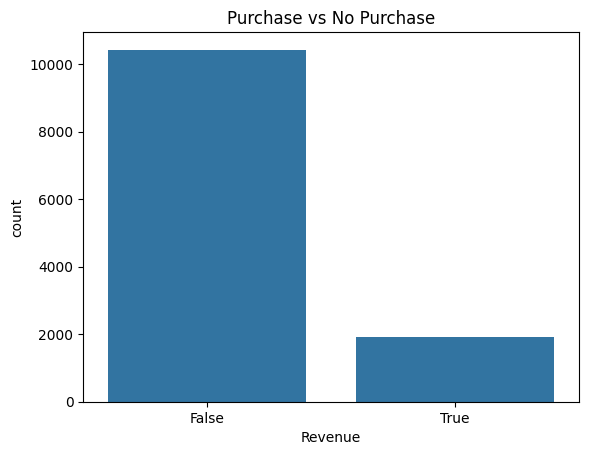

In [10]:
sns.countplot(data=df, x='Revenue')
plt.title('Purchase vs No Purchase')
plt.show()

In [11]:
df['VisitorType'].value_counts()

,count
VisitorType,
Returning_Visitor,10551
New_Visitor,1694
Other,85


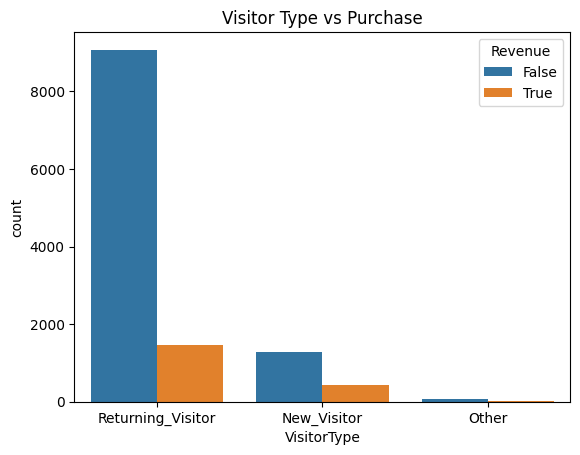

In [12]:
sns.countplot(data=df, x='VisitorType', hue='Revenue')
plt.title('Visitor Type vs Purchase')
plt.show()

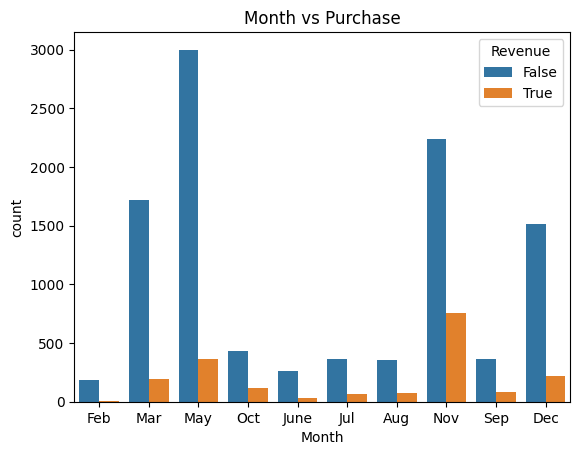

In [13]:
sns.countplot(data=df, x='Month', hue='Revenue')
plt.title('Month vs Purchase')
plt.show()

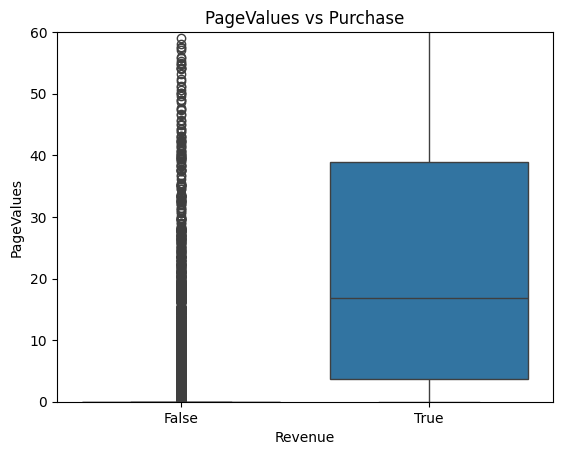

In [14]:
sns.boxplot(data=df, x='Revenue', y='PageValues')
plt.ylim(0, 60)
plt.title('PageValues vs Purchase')
plt.show()

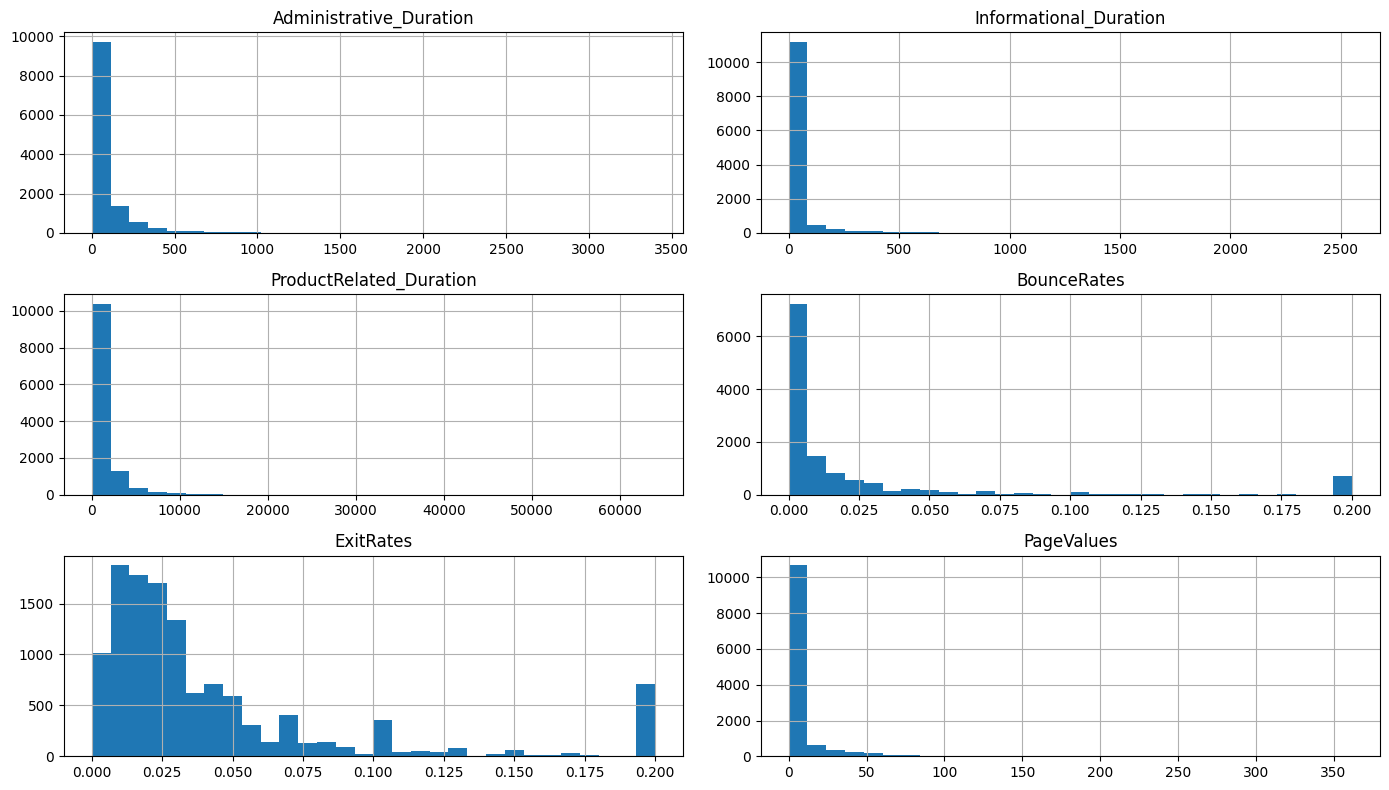

In [15]:
num_cols = ['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration',
            'BounceRates', 'ExitRates', 'PageValues']

df[num_cols].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

 Data Preprocessing

In [16]:
df = df.drop_duplicates()
df.shape

(12205, 18)

Outliers

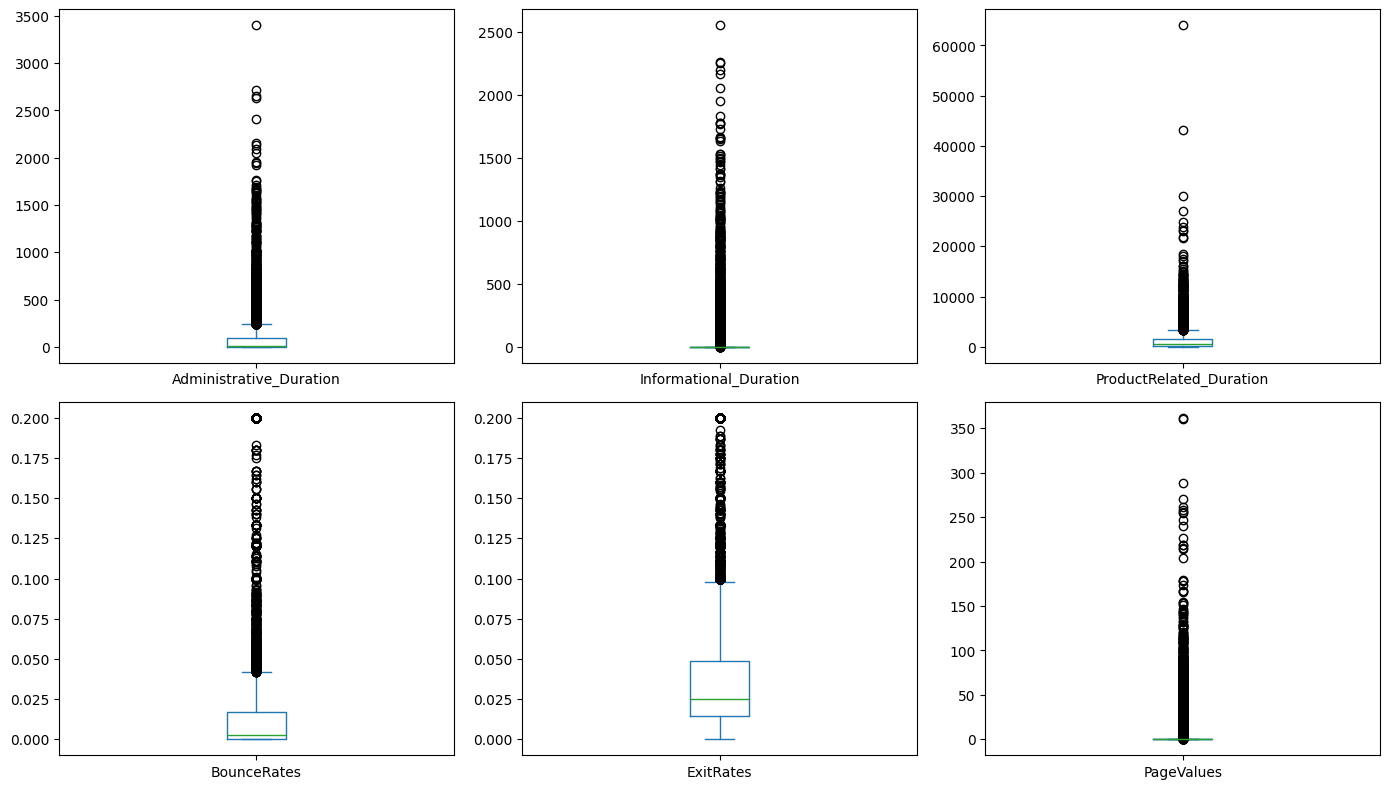

,0
Administrative_Duration,1149
Informational_Duration,2405
ProductRelated_Duration,951
BounceRates,1428
ExitRates,1325
PageValues,2730


In [17]:
df[num_cols].plot(kind='box', subplots=True, layout=(2, 3), figsize=(14, 8))
plt.tight_layout()
plt.show()

Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
outliers_count = ((df[num_cols] < Q1 - 1.5 * IQR) | (df[num_cols] > Q3 + 1.5 * IQR)).sum()
outliers_count

In [18]:
df['Revenue'] = df['Revenue'].astype(int)
df['Weekend'] = df['Weekend'].astype(int)

In [19]:
df = pd.get_dummies(df, columns=['Month', 'VisitorType'], drop_first=True, dtype=int)
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_Feb,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_Other,VisitorType_Returning_Visitor
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,1,0,0,0,0,0,0,0,0,1


Feature Extraction

In [20]:
df['TotalPages'] = df['Administrative'] + df['Informational'] + df['ProductRelated']
df['TotalDuration'] = df['Administrative_Duration'] + df['Informational_Duration'] + df['ProductRelated_Duration']
df['AvgTimePerPage'] = (df['TotalDuration'] / df['TotalPages']).replace([np.inf, -np.inf], np.nan).fillna(0)

df[['TotalPages', 'TotalDuration', 'AvgTimePerPage', 'Revenue']].corr()['Revenue']

,Revenue
TotalPages,0.161535
TotalDuration,0.153720
AvgTimePerPage,0.038116
Revenue,1.000000


Correlation

In [21]:
corr = df.corr()
corr['Revenue'].sort_values(ascending=False)

,Revenue
Revenue,1.000000
PageValues,0.491894
TotalPages,0.161535
ProductRelated,0.156042
Month_Nov,0.154274
TotalDuration,0.153720
ProductRelated_Duration,0.150077
Administrative,0.136330
Informational,0.093626
Administrative_Duration,0.091768


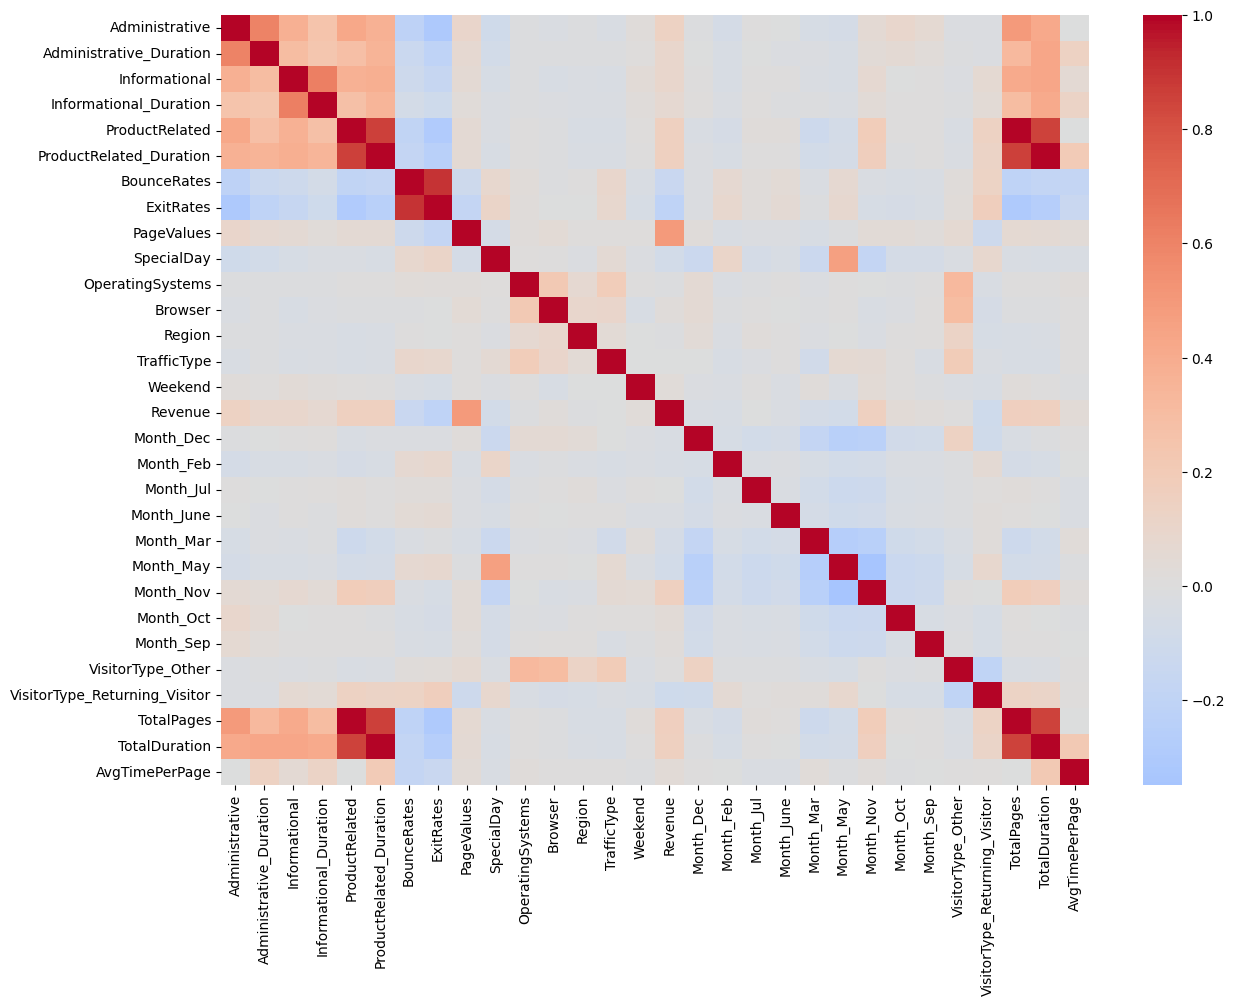

In [22]:
plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.show()

Assign data and labels

In [23]:
X = df.drop('Revenue', axis=1)
y = df['Revenue']

Split into Train and Test

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(9764, 29) (2441, 29)


In [25]:
cap_cols = num_cols + ['TotalDuration', 'AvgTimePerPage']

X_train = X_train.copy()
X_test = X_test.copy()

upper = X_train[cap_cols].quantile(0.99)
X_train[cap_cols] = X_train[cap_cols].clip(upper=upper, axis=1)
X_test[cap_cols] = X_test[cap_cols].clip(upper=upper, axis=1)

 Scale the data (fit on the training set only)

In [26]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

 Models

In [27]:
results = []
models = {}
preds = {}

Logistic Regression

In [28]:
lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

models['Logistic Regression'] = lr
preds['Logistic Regression'] = lr_pred
results.append(['Logistic Regression', accuracy_score(y_test, lr_pred), precision_score(y_test, lr_pred),
                recall_score(y_test, lr_pred), f1_score(y_test, lr_pred)])
print('Accuracy:', accuracy_score(y_test, lr_pred))

Accuracy: 0.8533387955755838


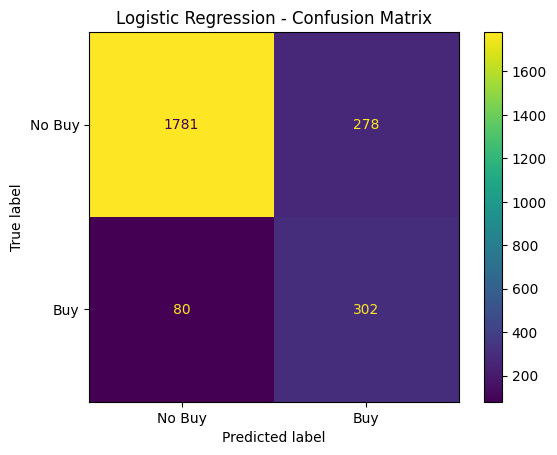

In [29]:
cm = confusion_matrix(y_test, lr_pred)
ConfusionMatrixDisplay(cm, display_labels=['No Buy', 'Buy']).plot()
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

Gradient Descent

In [30]:
gd = SGDClassifier(loss='log_loss', max_iter=1000, class_weight='balanced', random_state=42)
gd.fit(X_train, y_train)
gd_pred = gd.predict(X_test)

models['Gradient Descent'] = gd
preds['Gradient Descent'] = gd_pred
results.append(['Gradient Descent', accuracy_score(y_test, gd_pred), precision_score(y_test, gd_pred),
                recall_score(y_test, gd_pred), f1_score(y_test, gd_pred)])
print('Accuracy:', accuracy_score(y_test, gd_pred))

Accuracy: 0.820565342072921


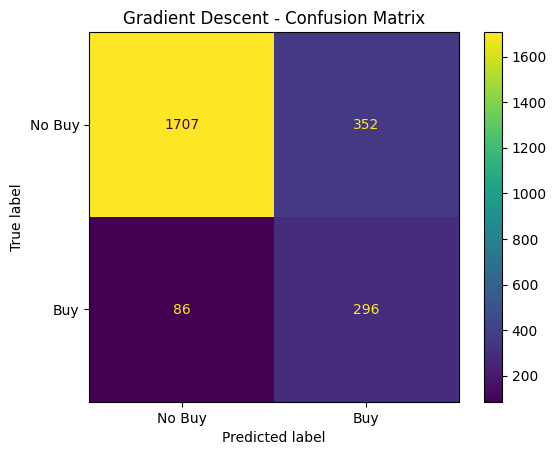

In [31]:
cm = confusion_matrix(y_test, gd_pred)
ConfusionMatrixDisplay(cm, display_labels=['No Buy', 'Buy']).plot()
plt.title('Gradient Descent - Confusion Matrix')
plt.show()

In [32]:
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

models['KNN'] = knn
preds['KNN'] = knn_pred
results.append(['KNN', accuracy_score(y_test, knn_pred), precision_score(y_test, knn_pred),
                recall_score(y_test, knn_pred), f1_score(y_test, knn_pred)])
print('Accuracy:', accuracy_score(y_test, knn_pred))

Accuracy: 0.8795575583777141


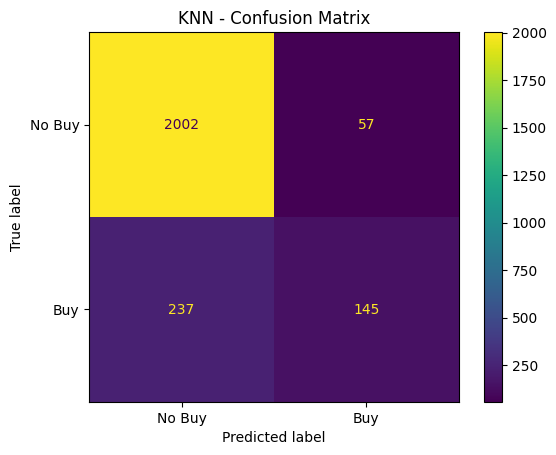

In [33]:
cm = confusion_matrix(y_test, knn_pred)
ConfusionMatrixDisplay(cm, display_labels=['No Buy', 'Buy']).plot()
plt.title('KNN - Confusion Matrix')
plt.show()

In [34]:
dt = DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

models['Decision Tree'] = dt
preds['Decision Tree'] = dt_pred
results.append(['Decision Tree', accuracy_score(y_test, dt_pred), precision_score(y_test, dt_pred),
                recall_score(y_test, dt_pred), f1_score(y_test, dt_pred)])
print('Accuracy:', accuracy_score(y_test, dt_pred))

Accuracy: 0.8570258090946333


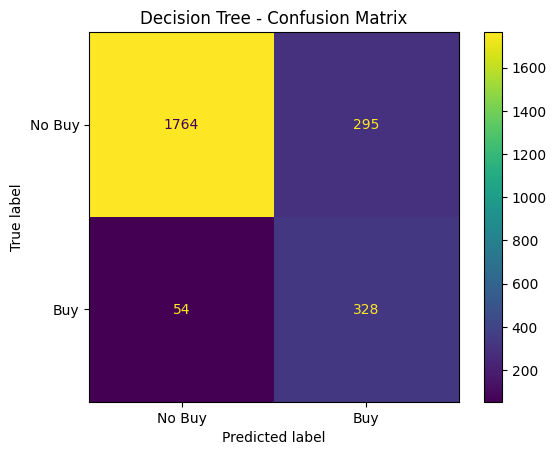

In [35]:
cm = confusion_matrix(y_test, dt_pred)
ConfusionMatrixDisplay(cm, display_labels=['No Buy', 'Buy']).plot()
plt.title('Decision Tree - Confusion Matrix')
plt.show()

feature_importances

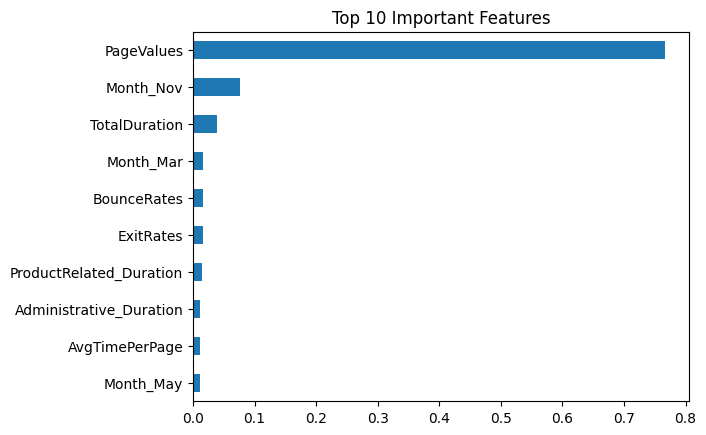

In [36]:
importance = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importance.sort_values().plot(kind='barh', title='Top 10 Important Features')
plt.show()

In [37]:
nb = GaussianNB()
nb.fit(X_train, y_train)
nb_pred = nb.predict(X_test)

models['Naive Bayes'] = nb
preds['Naive Bayes'] = nb_pred
results.append(['Naive Bayes', accuracy_score(y_test, nb_pred), precision_score(y_test, nb_pred),
                recall_score(y_test, nb_pred), f1_score(y_test, nb_pred)])
print('Accuracy:', accuracy_score(y_test, nb_pred))

Accuracy: 0.7468250716919296


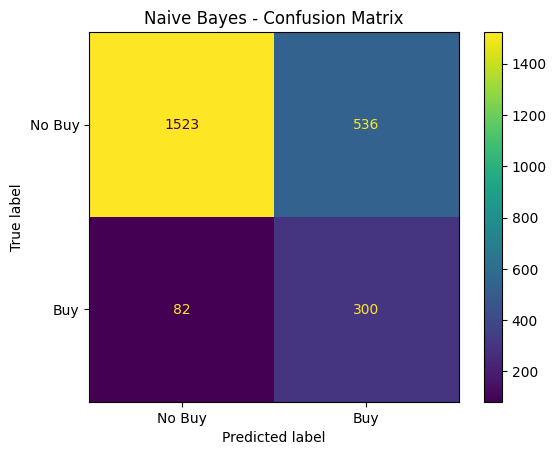

In [38]:
cm = confusion_matrix(y_test, nb_pred)
ConfusionMatrixDisplay(cm, display_labels=['No Buy', 'Buy']).plot()
plt.title('Naive Bayes - Confusion Matrix')
plt.show()

In [39]:
from sklearn.model_selection import GridSearchCV

# ---- Decision Tree (Tuned) ----
dt_grid = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param_grid={'max_depth': [3, 5, 7, 10],
                'min_samples_leaf': [1, 5, 10, 20],
                'criterion': ['gini', 'entropy']},
    scoring='f1', cv=5)
dt_grid.fit(X_train, y_train)
print('Best params:', dt_grid.best_params_)

dt_tuned = dt_grid.best_estimator_
dt_tuned_pred = dt_tuned.predict(X_test)
models['Decision Tree (Tuned)'] = dt_tuned
preds['Decision Tree (Tuned)'] = dt_tuned_pred
results.append(['Decision Tree (Tuned)', accuracy_score(y_test, dt_tuned_pred), precision_score(y_test, dt_tuned_pred),
                recall_score(y_test, dt_tuned_pred), f1_score(y_test, dt_tuned_pred)])
print('Accuracy:', accuracy_score(y_test, dt_tuned_pred), '| F1:', f1_score(y_test, dt_tuned_pred))

# ---- KNN (Tuned) ----
knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid={'n_neighbors': [3, 5, 7, 9, 11, 15],
                'weights': ['uniform', 'distance']},
    scoring='f1', cv=5)
knn_grid.fit(X_train, y_train)
print('Best params:', knn_grid.best_params_)

knn_tuned = knn_grid.best_estimator_
knn_tuned_pred = knn_tuned.predict(X_test)
models['KNN (Tuned)'] = knn_tuned
preds['KNN (Tuned)'] = knn_tuned_pred
results.append(['KNN (Tuned)', accuracy_score(y_test, knn_tuned_pred), precision_score(y_test, knn_tuned_pred),
                recall_score(y_test, knn_tuned_pred), f1_score(y_test, knn_tuned_pred)])
print('Accuracy:', accuracy_score(y_test, knn_tuned_pred), '| F1:', f1_score(y_test, knn_tuned_pred))

Best params: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 20}
Accuracy: 0.8570258090946333 | F1: 0.6513486513486514
Best params: {'n_neighbors': 5, 'weights': 'distance'}
Accuracy: 0.8795575583777141 | F1: 0.5164473684210527


In [40]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=15)
X_train_sel = selector.fit_transform(X_train, y_train)
X_test_sel = selector.transform(X_test)

selected_cols = X.columns[selector.get_support()]
print('Selected features:', list(selected_cols))

dt_sel = DecisionTreeClassifier(**dt_grid.best_params_, class_weight='balanced', random_state=42)
dt_sel.fit(X_train_sel, y_train)
dt_sel_pred = dt_sel.predict(X_test_sel)
print('Decision Tree (selected features)')
print('Accuracy:', accuracy_score(y_test, dt_sel_pred), '| Recall:', recall_score(y_test, dt_sel_pred), '| F1:', f1_score(y_test, dt_sel_pred))

lr_sel = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_sel.fit(X_train_sel, y_train)
lr_sel_pred = lr_sel.predict(X_test_sel)
print('Logistic Regression (selected features)')
print('Accuracy:', accuracy_score(y_test, lr_sel_pred), '| Recall:', recall_score(y_test, lr_sel_pred), '| F1:', f1_score(y_test, lr_sel_pred))

Selected features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month_May', 'Month_Nov', 'VisitorType_Returning_Visitor', 'TotalPages', 'TotalDuration']
Decision Tree (selected features)
Accuracy: 0.850880786562884 | Recall: 0.8691099476439791 | F1: 0.6459143968871596
Logistic Regression (selected features)
Accuracy: 0.8562064727570667 | Recall: 0.7853403141361257 | F1: 0.6309148264984227


ANN

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy: 0.8684965178205654 | Recall: 0.7356020942408377 | F1: 0.636466591166478


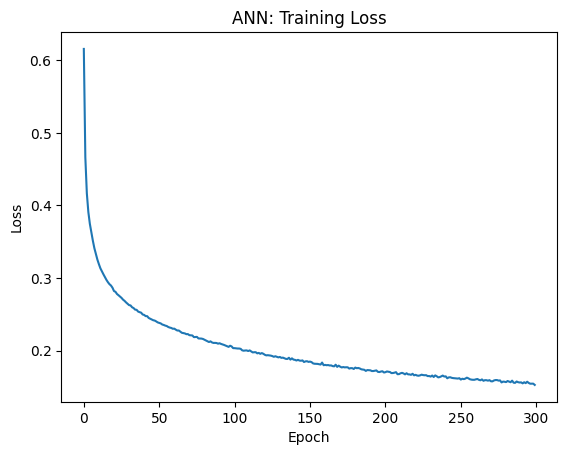

In [41]:
from sklearn.neural_network import MLPClassifier
from sklearn.utils import resample

pos = (y_train.values == 1)
X_pos, X_neg = X_train[pos], X_train[~pos]
X_pos_up = resample(X_pos, replace=True, n_samples=len(X_neg), random_state=42)

X_bal = np.vstack([X_neg, X_pos_up])
y_bal = np.array([0] * len(X_neg) + [1] * len(X_pos_up))


ann = MLPClassifier(hidden_layer_sizes=(32, 16), activation='relu', alpha=0.001,
                    max_iter=300, random_state=42)
ann.fit(X_bal, y_bal)
ann_pred = ann.predict(X_test)

models['ANN'] = ann
preds['ANN'] = ann_pred
results.append(['ANN', accuracy_score(y_test, ann_pred), precision_score(y_test, ann_pred),
                recall_score(y_test, ann_pred), f1_score(y_test, ann_pred)])
print('Accuracy:', accuracy_score(y_test, ann_pred), '| Recall:', recall_score(y_test, ann_pred), '| F1:', f1_score(y_test, ann_pred))

plt.plot(ann.loss_curve_)
plt.title('ANN: Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

Models Comparison

In [42]:
results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1']).set_index('Model').round(4)
results_df

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.8533,0.5207,0.7906,0.6279
Gradient Descent,0.8206,0.4568,0.7749,0.5748
KNN,0.8796,0.7178,0.3796,0.4966
Decision Tree,0.8570,0.5265,0.8586,0.6527
Naive Bayes,0.7468,0.3589,0.7853,0.4926
Decision Tree (Tuned),0.8570,0.5267,0.8534,0.6513
KNN (Tuned),0.8796,0.6947,0.4110,0.5164
ANN,0.8685,0.5609,0.7356,0.6365


In [43]:
from sklearn.metrics import roc_auc_score

results_df['ROC-AUC'] = pd.Series({name: roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]) for name, m in models.items()}).round(4)
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.8533,0.5207,0.7906,0.6279,0.9118
Gradient Descent,0.8206,0.4568,0.7749,0.5748,0.8905
KNN,0.8796,0.7178,0.3796,0.4966,0.8197
Decision Tree,0.8570,0.5265,0.8586,0.6527,0.9216
Naive Bayes,0.7468,0.3589,0.7853,0.4926,0.8344
Decision Tree (Tuned),0.8570,0.5267,0.8534,0.6513,0.9287
KNN (Tuned),0.8796,0.6947,0.4110,0.5164,0.8104
ANN,0.8685,0.5609,0.7356,0.6365,0.8993


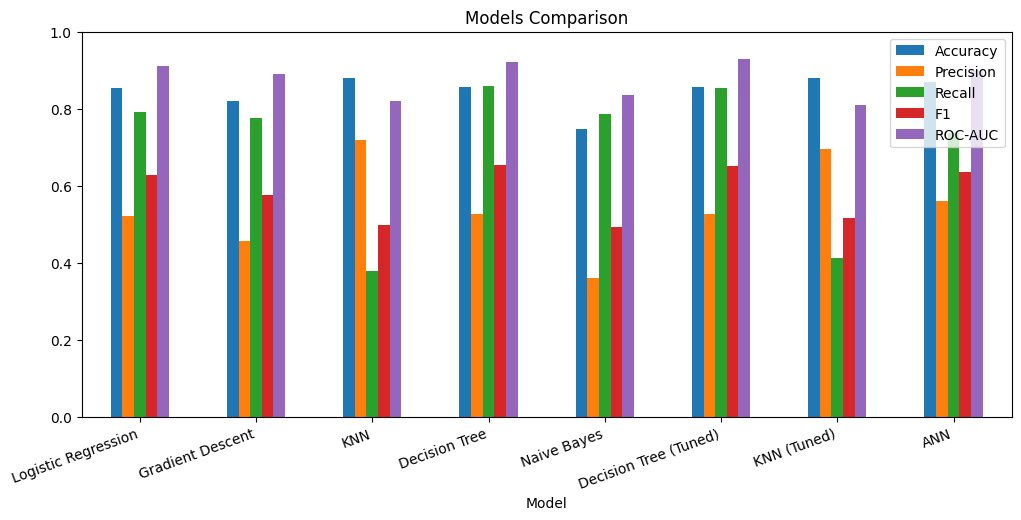

In [44]:
results_df.plot(kind='bar', figsize=(12, 5))
plt.title('Models Comparison')
plt.ylim(0, 1)
plt.xticks(rotation=20, ha='right')
plt.show()

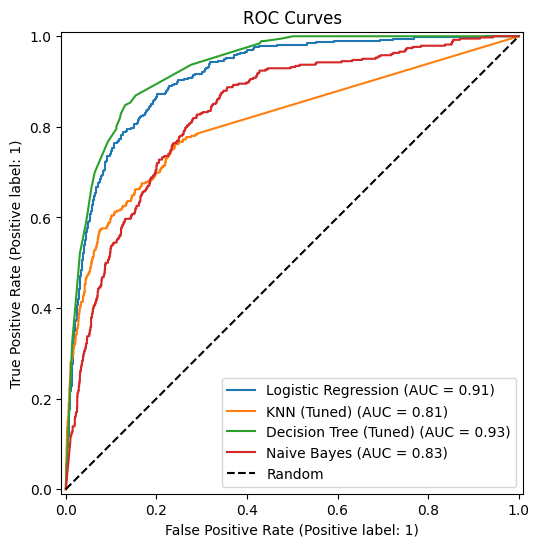

In [45]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(models['Logistic Regression'], X_test, y_test, name='Logistic Regression', ax=ax)
RocCurveDisplay.from_estimator(models['KNN (Tuned)'], X_test, y_test, name='KNN (Tuned)', ax=ax)
RocCurveDisplay.from_estimator(models['Decision Tree (Tuned)'], X_test, y_test, name='Decision Tree (Tuned)', ax=ax)
RocCurveDisplay.from_estimator(models['Naive Bayes'], X_test, y_test, name='Naive Bayes', ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='Random')
ax.set_title('ROC Curves')
ax.legend()
plt.show()

In [46]:
#best_name = results_df['F1'].idxmax()
#print('Best model (by F1):', best_name)
#print()
#print(classification_report(y_test, preds[best_name], target_names=['No Buy', 'Buy']))

Final Model Selection

In [47]:
best_name = results_df['ROC-AUC'].idxmax()
print('Best model (by ROC-AUC):', best_name)
print()
print(classification_report(y_test, preds[best_name], target_names=['No Buy', 'Buy']))

Best model (by ROC-AUC): Decision Tree (Tuned)

              precision    recall  f1-score   support

      No Buy       0.97      0.86      0.91      2059
         Buy       0.53      0.85      0.65       382

    accuracy                           0.86      2441
   macro avg       0.75      0.86      0.78      2441
weighted avg       0.90      0.86      0.87      2441



In [48]:
import joblib

In [49]:
joblib.dump(models[best_name], 'model.joblib')
joblib.dump(scaler, 'scaler.joblib')
joblib.dump(list(X.columns), 'columns.joblib')

['columns.joblib']

In [50]:
joblib.dump(upper, 'cap_limits.joblib')

import sklearn
print(sklearn.__version__)

1.6.1
